fs = 10 Hz | k = 1 | alias = 3 Hz
fs = 12 Hz | k = 1 | alias = 5 Hz
fs = 14 Hz | k = 0 | alias = 7 Hz
fs = 20 Hz | k = 0 | alias = 7 Hz


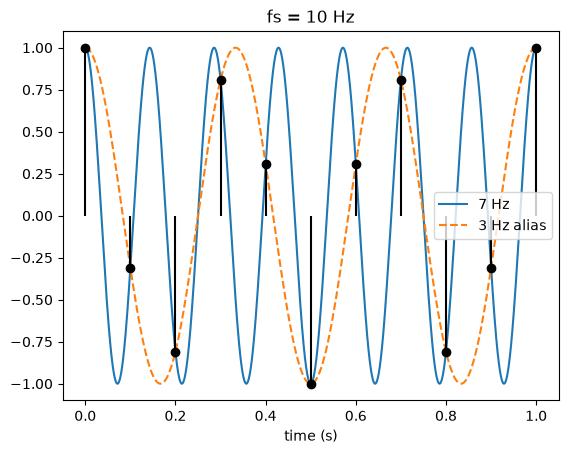

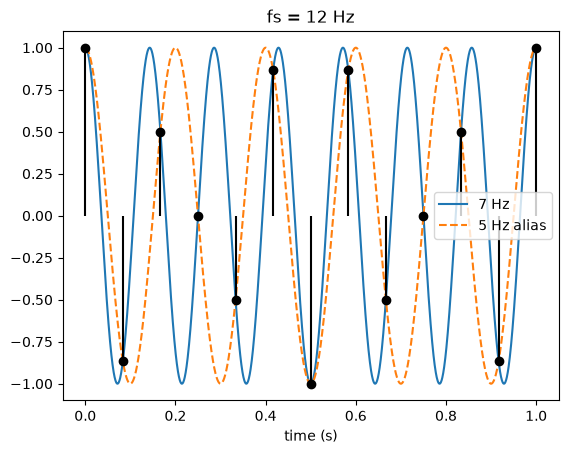

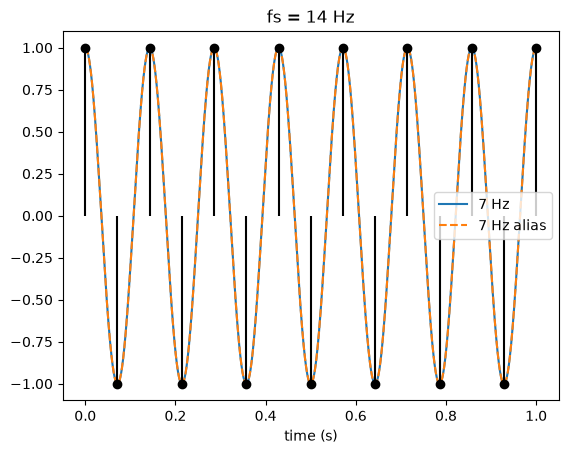

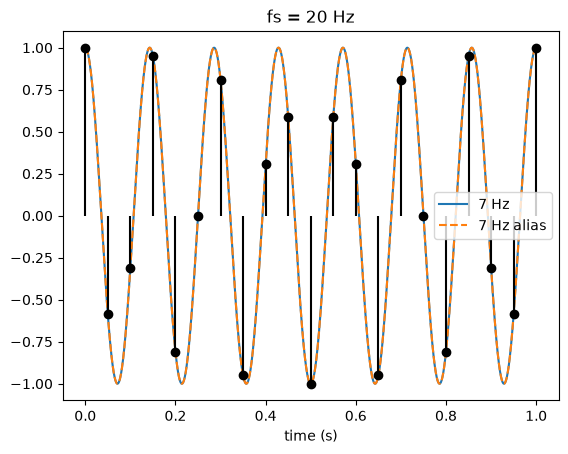

In [1]:
import numpy as np
import matplotlib.pyplot as plt

f0 = 7.0
t = np.linspace(0, 1, 2000)          # dense grid = "analog" signal

for fs in [10.0, 12.0, 14.0, 20.0]:
    n = np.arange(0, int(fs) + 1)
    tn = n / fs
    f_alias = abs(f0 - fs*round(f0/fs))
    k = round(f0/fs)
    print(f"fs = {fs:g} Hz | k = {k} | alias = {f_alias:g} Hz")

    plt.figure()
    plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0:g} Hz")
    plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias:g} Hz alias")
    plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
    plt.title(f"fs = {fs:g} Hz")
    plt.xlabel("time (s)")
    plt.legend()

plt.show()

In [2]:
import os
import numpy as np
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

In [ ]:
fname = "mk.wav"          
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
else:                     
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)

print("fs =", fs, "Hz, samples =", len(x))

fs = 44100 Hz, samples = 297980


In [4]:
Audio(x, rate=fs)

In [5]:
for k in [2, 4, 8]:
    naive  = x[::k]                                   
    proper = signal.decimate(x, k, ftype="fir")       
    print(k, "new fs =", fs // k, "Hz")
    print("  naive (no filter):")
    display(Audio(naive, rate=fs//k))
    print("  decimate (with filter):")
    display(Audio(proper, rate=fs//k))

2 new fs = 22050 Hz
  naive (no filter):


  decimate (with filter):


4 new fs = 11025 Hz
  naive (no filter):


  decimate (with filter):


8 new fs = 5512 Hz
  naive (no filter):


  decimate (with filter):


In [6]:
import matplotlib.pyplot as plt
%matplotlib inline

In [7]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

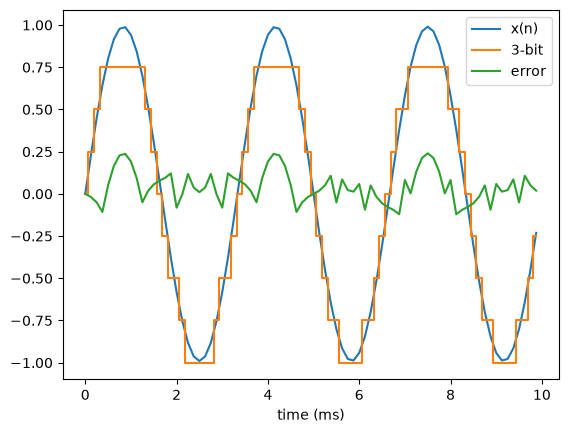

In [8]:
fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)
plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.xlabel("time (ms)"); plt.legend(); plt.show()

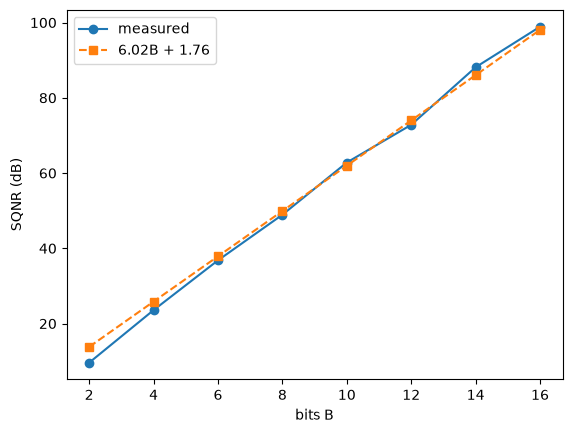

In [9]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(x**2)/np.sum((x - quantize(x, B))**2)) for B in bits]
plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02*bits + 1.76, "s--", label="6.02B + 1.76")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)"); plt.legend(); plt.show()

In [10]:
print("B   measured  theory")
for B, m in zip(bits, meas):
    print(f"{B:2d}  {m:7.2f}  {6.02*B + 1.76:7.2f}")

B   measured  theory
 2     9.60    13.80
 4    23.58    25.84
 6    36.81    37.88
 8    48.93    49.92
10    62.81    61.96
12    72.84    74.00
14    88.13    86.04
16    98.91    98.08


In [11]:
print("slope =", np.polyfit(bits, meas, 1)[0], "dB per bit")

slope = 6.368190334492777 dB per bit


-Each extra bit raises SQNR by about 6 dB, so the measured line follows 6.02B + 1.76.
-The measured values deviate by 1 to 4 dB. At low B this is partly due to clipping at the peaks (0.99 exceeds the top level 1 − Δ), and at high B because the signal has only 80 samples.
Example: from 8 to 16 bits the gain is about 50 dB, or 6.25 dB per bit.

In [13]:
fname = "mk.wav"
fs, x = wavfile.read(fname)
x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
x = x / np.max(np.abs(x))
print("fs =", fs, "Hz, samples =", len(x), ", duration =", round(len(x)/fs, 2), "s")

fs = 44100 Hz, samples = 297980 , duration = 6.76 s


In [14]:
for B in [4, 8, 12]:
    xq = quantize(x, B)
    e = x - xq
    sqnr = 10*np.log10(np.sum(x**2)/np.sum(e**2))
    print(f"B = {B:2d} bits | measured SQNR = {sqnr:6.2f} dB | sine theory = {6.02*B + 1.76:6.2f} dB")
    display(Audio(xq, rate=fs))

B =  4 bits | measured SQNR =  13.66 dB | sine theory =  25.84 dB


B =  8 bits | measured SQNR =  35.30 dB | sine theory =  49.92 dB


B = 12 bits | measured SQNR =  59.37 dB | sine theory =  74.00 dB


In [15]:
rms = np.sqrt(np.mean(x**2))
print("RMS =", round(rms, 3), "| peak/RMS =", round(1/rms, 2), "=", round(20*np.log10(1/rms), 2), "dB")

RMS = 0.13 | peak/RMS = 7.67 = 17.7 dB


 Analysis questions

1. Why does a 7 Hz tone appear at 3 Hz when fs = 10 Hz?

Sampling repeats the spectrum around every multiple of fs. The tone sits at ±7 Hz; replicas appear at 7 ± 10k, including −3 Hz and +3 Hz.

    frequency (Hz), fs = 10, Nyquist = 5

    -17      -10      -7  -3   0   3   7      10      17
     |--------|--------|---|---|---|---|--------|--------|
                         *   o       o   *    (* original ±7, o alias ±3)
                       |<- visible band: -5 to +5 ->|

The ±7 Hz components lie outside the visible band of ±fs/2 = ±5 Hz, while the replicas at ±3 Hz fall inside it. The sampled signal therefore appears at |7 − 10| = 3 Hz.

2. Why can the aliasing in the naive version not be removed afterwards?

After sampling, a 7 Hz and a 3 Hz cosine give identical samples (verified in Task 2.1), so the data holds no record of which was the original. A filter applied afterwards cannot separate the alias from a real 3 Hz component. The anti-aliasing filter must act before sampling.

3. By how much does SQNR change per added bit? Does the measurement agree?

Each bit halves Δ, so the noise power drops by 4 and SQNR rises by 10·log10(4) = 6.02 dB. My measured slope was about 6.4 dB per bit (Task 2.4), and 6.02 dB per bit between 8 and 12 bits for my voice (Task 2.5), so the measurement agrees.

4. Temperature sensor (0.1 °C/s, 0.01 °C resolution, 0 to 100 °C)

Bits: 100/0.01 = 10,000 levels needed. 2^13 = 8,192 is too few and 2^14 = 16,384 is enough, so B = 14 bits (Δ = 100/2^14 ≈ 0.0061 °C).

Sampling rate: the signal changes very slowly, so the Nyquist limit is tiny. I choose fs = 1 Hz, so the temperature moves by at most 0.1 °C between samples. To keep the change below one resolution step (0.01 °C) per sample, use fs = 10 Hz. An analog low-pass anti-aliasing filter is needed before the converter to keep noise and mains interference from aliasing.

 Listening observations
- Task 2.2, k = 8, naive: ( harsh and metallic, with whistling on "s" sounds that were not in the original.)
- Task 2.2, k = 8, decimate: (clean but muffled, like a telephone, with no extra tones)
- Task 2.5, 4 bits: (grainy and noisy, with crackling that follows my voice.)
- Task 2.5, 8 bits: (a faint background hiss, but the speech is clear.)
- Task 2.5, 12 bits: (very close to the original)

AI-use statement
I used an AI assistant to help set up Python and Jupyter, understand the code and theory, and check my explanations. I ran all code myself on my own recording and did the listening myself.